# Rolling market betas and beta-decile sorts (CRSP monthly)

**Idea in four steps**
1. For every stock and month *t*, regress the stock's excess return on the market's excess return over the **previous W months** (ending at *t*). The slope is the beta: `beta = Cov(stock, market) / Var(market)`.
2. At the end of month *t*, rank all stocks by beta and split them into 10 groups (decile 1 = lowest beta, 10 = highest).
3. Hold each decile during month *t+1* and record its return (equal-weighted and value-weighted).
4. Summarize each decile: average return, CAPM alpha, realized beta.

**No look-ahead:** the beta used at *t* only contains data up to *t*; the return measured is *t+1*.

## 1. Settings (the only cell you need to edit)

In [ ]:
CRSP_PATH   = "/Users/daniilg/Downloads/crsp_monthly_1963_2026.parquet"
MARKET_PATH = None      # monthly file with columns: date, mkt_ret [, rf]  (decimals). None = CRSP proxy, NOT SPX
OUT_DIR     = "beta_out"

# window length in months, and the minimum months of data required to report a beta
WINDOWS = {"6m": 6, "1y": 12, "2y": 24, "5y": 60, "10y": 120}
MIN_OBS = {"6m": 6, "1y": 12, "2y": 24, "5y": 36, "10y": 60}

## 2. Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs(OUT_DIR, exist_ok=True)

## 3. Load the stock data

Keep common stocks and put every date on the month-end. Then reshape to a **date x stock** table for returns (`R`) and market cap (`mcap`), so each column is one stock.

In [ ]:
df = pd.read_parquet(CRSP_PATH, columns=["permno", "date", "ret", "mktcap", "shrcd"])
df = df[df.shrcd.isin([10, 11])]                       # common stocks
df["date"] = df["date"] + pd.offsets.MonthEnd(0)

R    = df.pivot(index="date", columns="permno", values="ret")
mcap = df.pivot(index="date", columns="permno", values="mktcap")

# make sure no calendar month is skipped, so "6 rows" always means "6 months"
months = pd.date_range(R.index.min(), R.index.max(), freq="ME")   # use "M" on pandas < 2.2
R, mcap = R.reindex(months), mcap.reindex(months)
print(f"{R.shape[1]:,} stocks, {R.shape[0]} months, {R.index.min():%Y-%m} to {R.index.max():%Y-%m}")

26,519 stocks, 765 months, 1963-01 to 2026-09


## 4. Market return (and risk-free rate)

If `MARKET_PATH` is set, read it. Otherwise build a **proxy**: the value-weighted average return of all stocks in the file, weighted by *last month's* market cap. The proxy is close to the S&P 500 but is **not** the S&P 500.

In [ ]:
if MARKET_PATH:
    m = pd.read_parquet(MARKET_PATH) if MARKET_PATH.endswith(".parquet") else pd.read_csv(MARKET_PATH)
    m["date"] = pd.to_datetime(m["date"]) + pd.offsets.MonthEnd(0)
    m = m.set_index("date").sort_index()
    mkt = m["mkt_ret"]
    rf  = m["rf"] if "rf" in m else pd.Series(0.0, index=m.index)
    print("Market: user file")
else:
    w   = mcap.shift(1).where(R.notna())               # last month's cap, only for stocks with a return
    mkt = (R * w).sum(axis=1) / w.sum(axis=1)
    rf  = pd.Series(0.0, index=mkt.index)
    print("Market: value-weighted CRSP proxy (NOT SPX)")

mkt, rf = mkt.reindex(months), rf.reindex(months).fillna(0.0)

R_ex   = R.sub(rf, axis=0)      # stock excess returns
mkt_ex = mkt - rf               # market excess returns

Market: value-weighted CRSP proxy (NOT SPX)


## 5. Rolling betas

For each window, compute `Cov(stock, market) / Var(market)` over the last W months. Only months where the stock has a return are used (the market is blanked out in other months, so both sides use the same months). A beta is reported only if the stock has at least `MIN_OBS` months in the window **and** has a return this month, which stops delisted stocks from keeping a stale beta.

*Why you may see NaN in short-window columns:* if a stock stopped reporting for a while and came back, its last 6 months to 5 years may hold too few observations, while the 10-year window still reaches back to older data. The 10-year beta can then exist while the others are NaN.

In [ ]:
def rolling_beta(R_ex, mkt_ex, window, min_obs):
    # market return, but blank wherever the stock has no return, so both use the same months
    M = pd.DataFrame(np.where(R_ex.notna(), mkt_ex.values[:, None], np.nan),
                     index=R_ex.index, columns=R_ex.columns)
    cov = R_ex.rolling(window, min_periods=min_obs).cov(M)
    var = M.rolling(window, min_periods=min_obs).var()
    return (cov / var).where(R_ex.notna())             # only report betas for stocks trading this month


betas = {name: rolling_beta(R_ex, mkt_ex, WINDOWS[name], MIN_OBS[name]) for name in WINDOWS}

for name, b in betas.items():
    print(f"{name:>3}: average beta across stocks = {b.mean(axis=1).mean():.2f}")

# save in long format: one row per (date, stock)
beta_long = pd.concat({k: v.stack() for k, v in betas.items()}, axis=1)
beta_long.columns = [f"beta_{k}" for k in beta_long.columns]
beta_long.to_parquet(f"{OUT_DIR}/betas_all.parquet")
beta_long.tail()

 6m: average beta across stocks = 1.10
 1y: average beta across stocks = 1.13
 2y: average beta across stocks = 1.15
 5y: average beta across stocks = 1.14
10y: average beta across stocks = 1.14


,,beta_6m,beta_1y,beta_2y,beta_5y,beta_10y
,permno,,,,,
2026-04-30,92449,NaN,NaN,NaN,NaN,1.266223
2026-06-30,89411,NaN,NaN,NaN,NaN,2.653066
2026-07-31,89411,NaN,NaN,NaN,NaN,2.615961
2026-08-31,89411,NaN,NaN,NaN,NaN,2.604612
2026-09-30,89411,NaN,NaN,NaN,NaN,2.608224


## 6. Decile sorts

Each month *t*: rank stocks by beta, cut into 10 equal-sized groups, and record each group's average return in month *t+1*.
- **Equal-weighted:** every stock in the decile counts the same. **Value-weighted:** bigger companies count more (weighted by market cap at *t*), so large stocks dominate.
- **D1 (low beta)** = the 10% of stocks with the lowest betas, **D10 (high beta)** = the 10% with the highest.
- **High-Low** = D10 return minus D1 return each month (buy high beta, short low beta). If beta were rewarded, this would be positive.

In [ ]:
# portfolio names: decile 1 = lowest beta stocks, decile 10 = highest beta stocks
PORTFOLIOS = ["D1 (low beta)"] + [f"D{k}" for k in range(2, 10)] + ["D10 (high beta)"]


def decile_sort(beta, R, mcap, min_stocks=100):
    next_ret = R.shift(-1)                                         # return in month t+1
    ok       = beta.notna() & next_ret.notna() & mcap.notna()      # stocks we can actually sort and measure
    beta, next_ret, cap = beta.where(ok), next_ret.where(ok), mcap.where(ok)

    pct    = beta.rank(axis=1, pct=True)                           # 0-1 rank within each month
    decile = np.ceil(pct * 10).clip(1, 10)                         # 1 (lowest beta) ... 10 (highest)

    out = {}
    for k in range(1, 11):
        in_k  = decile == k
        label = PORTFOLIOS[k - 1]
        out[("Equal-weighted", label)] = next_ret.where(in_k).mean(axis=1)
        out[("Value-weighted", label)] = (next_ret * cap).where(in_k).sum(axis=1) / cap.where(in_k).sum(axis=1)
    out = pd.DataFrame(out)
    out = out[ok.sum(axis=1) >= min_stocks]                        # skip months with too few stocks

    out.index = out.index + pd.offsets.MonthEnd(1)                 # label by the month the return is earned
    for wt in ("Equal-weighted", "Value-weighted"):
        out[(wt, "High-Low")] = out[(wt, PORTFOLIOS[-1])] - out[(wt, PORTFOLIOS[0])]
    return out


sorts = {name: decile_sort(betas[name], R, mcap) for name in WINDOWS}
for name, s in sorts.items():
    s.to_csv(f"{OUT_DIR}/decile_returns_{name}.csv")
sorts["5y"].tail()          # columns: (weighting, portfolio)

,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted,...,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted,Equal-weighted,Value-weighted
,D1 (low beta),D1 (low beta),D2,D2,D3,D3,D4,D4,D5,D5,...,D7,D7,D8,D8,D9,D9,D10 (high beta),D10 (high beta),High-Low,High-Low
2026-05-31,0.056617,-0.012906,0.009192,0.013200,0.017035,-0.034620,0.005465,0.031334,0.021400,0.027730,...,0.024301,0.010902,0.071771,0.066049,0.055379,0.164726,0.156923,0.122827,0.100306,0.135733
2026-06-30,-0.011479,0.011050,0.057244,0.028341,0.039866,0.029925,0.034367,0.019403,0.038564,0.048074,...,0.035113,-0.025440,0.024136,-0.053846,0.000424,0.001761,-0.034625,0.022076,-0.023147,0.011026
2026-07-31,-0.041233,0.057178,-0.004573,0.019152,-0.004263,0.018310,0.005728,0.060060,0.015909,0.028286,...,-0.038352,-0.001999,-0.050442,-0.006681,-0.091396,-0.156219,-0.153244,-0.121804,-0.112012,-0.178982
2026-08-31,0.052281,0.034775,0.022988,0.026273,0.022266,-0.012958,0.035594,0.032177,0.041691,0.025235,...,0.010094,-0.010083,0.009377,-0.006612,0.027773,0.083950,0.046233,0.077102,-0.006048,0.042328
2026-09-30,-0.070390,-0.032899,-0.076259,-0.044937,-0.055538,-0.044951,-0.061833,-0.053910,-0.055665,-0.061091,...,-0.075944,0.018485,-0.050910,-0.034930,-0.036380,-0.000691,-0.039411,0.082055,0.030979,0.114954


## 7. Performance of each decile

For each portfolio: average excess return (% per month), **alpha** (the part not explained by the market), **realized beta** (how much it really moves with the market), and t-stats. Ordinary OLS t-stats are used, not Newey-West. HL is already a long-short return, so no risk-free rate is subtracted.

In [ ]:
def summarize(port, mkt_ex, rf):
    rows = {}
    for col in port.columns:                                       # col = (weighting, portfolio)
        y = port[col] if col[1] == "High-Low" else port[col] - rf.reindex(port.index)
        y = y.dropna()
        X = np.column_stack([np.ones(len(y)), mkt_ex.reindex(y.index)])     # regress on a constant + market
        coef = np.linalg.lstsq(X, y.values, rcond=None)[0]
        resid = y.values - X @ coef
        se = np.sqrt(np.diag(resid @ resid / (len(y) - 2) * np.linalg.inv(X.T @ X)))
        rows[col] = {"mean_%/mo": 100 * y.mean(),
                     "t_mean": y.mean() / (y.std() / np.sqrt(len(y))),
                     "alpha_%/mo": 100 * coef[0], "t_alpha": coef[0] / se[0],
                     "realized_beta": coef[1],
                     "sharpe_ann": np.sqrt(12) * y.mean() / y.std(),
                     "months": len(y)}
    return pd.DataFrame(rows).T                                     # rows = (weighting, portfolio)


summaries = {name: summarize(sorts[name], mkt_ex, rf) for name in WINDOWS}
for name, s in summaries.items():
    s.to_csv(f"{OUT_DIR}/decile_summary_{name}.csv")

for name in WINDOWS:
    print(f"\nValue-weighted deciles, sorted on {name} beta")
    display(summaries[name].loc["Value-weighted"].round(3))


Value-weighted deciles, sorted on 6m beta


,mean_%/mo,t_mean,alpha_%/mo,t_alpha,realized_beta,sharpe_ann,months
D1 (low beta),0.765,3.905,-0.147,-1.171,0.948,0.491,758.0
D2,0.905,5.554,0.078,0.894,0.860,0.699,758.0
D3,0.937,6.176,0.144,1.937,0.824,0.777,758.0
D4,1.038,6.887,0.220,3.465,0.850,0.866,758.0
D5,0.998,6.332,0.115,2.103,0.918,0.797,758.0
D6,1.076,6.279,0.099,1.958,1.015,0.790,758.0
D7,1.058,5.629,-0.010,-0.173,1.110,0.708,758.0
D8,1.000,4.803,-0.144,-1.746,1.189,0.604,758.0
D9,1.024,4.159,-0.303,-2.825,1.379,0.523,758.0
D10 (high beta),1.067,3.268,-0.536,-2.831,1.666,0.411,758.0



Value-weighted deciles, sorted on 1y beta


,mean_%/mo,t_mean,alpha_%/mo,t_alpha,realized_beta,sharpe_ann,months
D1 (low beta),0.623,3.455,-0.165,-1.339,0.825,0.436,752.0
D2,0.920,6.411,0.208,2.650,0.745,0.810,752.0
D3,0.892,6.108,0.150,2.002,0.777,0.772,752.0
D4,1.025,6.722,0.210,3.253,0.853,0.849,752.0
D5,1.153,7.114,0.264,4.452,0.930,0.899,752.0
D6,1.005,5.709,0.028,0.477,1.023,0.721,752.0
D7,1.008,5.104,-0.088,-1.329,1.148,0.645,752.0
D8,0.999,4.507,-0.209,-2.473,1.265,0.569,752.0
D9,1.076,4.198,-0.289,-2.611,1.429,0.530,752.0
D10 (high beta),1.217,3.581,-0.445,-2.313,1.741,0.452,752.0



Value-weighted deciles, sorted on 2y beta


,mean_%/mo,t_mean,alpha_%/mo,t_alpha,realized_beta,sharpe_ann,months
D1 (low beta),0.714,4.614,0.059,0.552,0.690,0.588,740.0
D2,0.810,5.799,0.167,1.955,0.678,0.738,740.0
D3,0.997,6.968,0.285,3.905,0.751,0.887,740.0
D4,1.099,7.193,0.303,4.609,0.839,0.916,740.0
D5,1.055,6.199,0.145,2.285,0.959,0.789,740.0
D6,0.971,5.296,-0.025,-0.407,1.050,0.674,740.0
D7,1.035,5.046,-0.076,-1.096,1.171,0.643,740.0
D8,1.028,4.561,-0.181,-2.196,1.274,0.581,740.0
D9,1.038,3.849,-0.352,-2.887,1.465,0.490,740.0
D10 (high beta),1.200,3.488,-0.465,-2.461,1.755,0.444,740.0



Value-weighted deciles, sorted on 5y beta


,mean_%/mo,t_mean,alpha_%/mo,t_alpha,realized_beta,sharpe_ann,months
D1 (low beta),0.894,6.525,0.389,3.657,0.532,0.838,728.0
D2,0.872,6.457,0.259,3.137,0.646,0.829,728.0
D3,1.038,7.030,0.318,4.143,0.758,0.903,728.0
D4,0.951,5.955,0.133,1.912,0.862,0.765,728.0
D5,1.019,5.805,0.097,1.445,0.973,0.745,728.0
D6,1.069,5.561,0.048,0.707,1.076,0.714,728.0
D7,0.919,4.360,-0.208,-2.943,1.188,0.560,728.0
D8,0.962,4.147,-0.269,-3.262,1.298,0.532,728.0
D9,1.069,3.850,-0.348,-2.827,1.494,0.494,728.0
D10 (high beta),1.098,3.237,-0.555,-3.144,1.742,0.416,728.0



Value-weighted deciles, sorted on 10y beta


,mean_%/mo,t_mean,alpha_%/mo,t_alpha,realized_beta,sharpe_ann,months
D1 (low beta),0.893,6.663,0.416,3.922,0.495,0.870,704.0
D2,0.830,5.912,0.218,2.407,0.635,0.772,704.0
D3,1.003,6.558,0.250,3.318,0.781,0.856,704.0
D4,1.069,6.208,0.198,2.584,0.905,0.811,704.0
D5,1.041,5.776,0.104,1.490,0.973,0.754,704.0
D6,0.963,4.881,-0.069,-0.944,1.072,0.637,704.0
D7,1.064,4.951,-0.057,-0.707,1.164,0.646,704.0
D8,0.994,4.240,-0.238,-2.797,1.279,0.554,704.0
D9,1.132,4.090,-0.275,-2.277,1.461,0.534,704.0
D10 (high beta),1.027,3.247,-0.539,-3.526,1.627,0.424,704.0


In [ ]:
# High-minus-low across windows (equal-weighted and value-weighted)
pd.concat({(wt, name): summaries[name].loc[(wt, "High-Low")]
           for wt in ("Equal-weighted", "Value-weighted") for name in WINDOWS}, axis=1).T.round(3)

mean_%/mo  t_mean  alpha_%/mo  t_alpha  realized_beta  \
Equal-weighted 6m      -0.087  -0.524      -0.563   -3.749          0.494   
               1y      -0.003  -0.017      -0.702   -4.309          0.731   
               2y       0.107   0.457      -0.765   -4.176          0.920   
               5y       0.047   0.184      -0.939   -4.893          1.040   
               10y      0.060   0.233      -0.954   -5.038          1.053   
Value-weighted 6m       0.302   1.162      -0.389   -1.636          0.718   
               1y       0.595   2.112      -0.280   -1.146          0.916   
               2y       0.486   1.629      -0.524   -2.129          1.065   
               5y       0.204   0.653      -0.944   -3.880          1.210   
               10y      0.134   0.462      -0.955   -4.302          1.132   

                    sharpe_ann  months  
Equal-weighted 6m       -0.066   758.0  
               1y       -0.002   752.0  
               2y        0.058   740.0  
               5y        0.024   728.0  
               10y       0.030   704.0  
Value-weighted 6m        0.146   758.0  
               1y        0.267   752.0  
               2y        0.207   740.0  
               5y        0.084   728.0  
               10y       0.060   704.0

## 8. Plot (value-weighted)

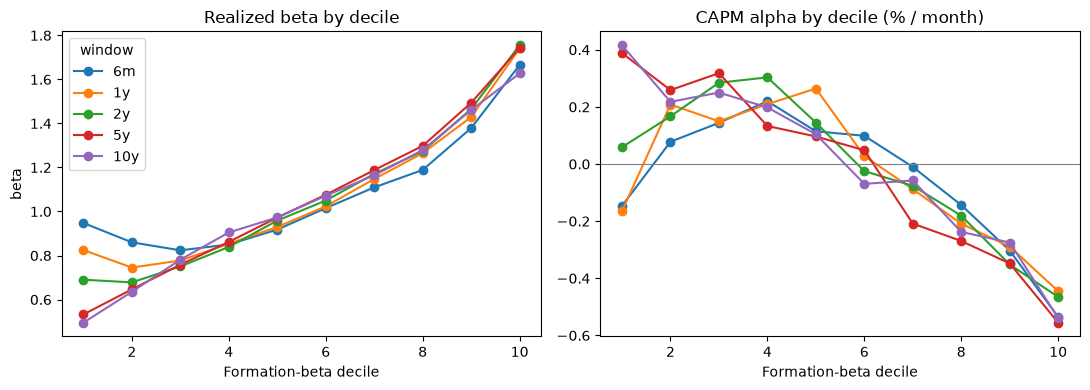

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for name in WINDOWS:
    s = summaries[name].loc["Value-weighted"].loc[PORTFOLIOS]
    axes[0].plot(range(1, 11), s["realized_beta"], marker="o", label=name)
    axes[1].plot(range(1, 11), s["alpha_%/mo"], marker="o", label=name)
axes[0].set(title="Realized beta by decile", xlabel="Formation-beta decile", ylabel="beta")
axes[1].set(title="CAPM alpha by decile (% / month)", xlabel="Formation-beta decile")
axes[1].axhline(0, color="grey", lw=0.8)
axes[0].legend(title="window")
plt.tight_layout(); plt.show()

## 9. Not included
- **1-month beta:** monthly data has one observation per month. It needs daily returns: regress each stock's daily excess returns on the market's within each month (require ~15 days), then reuse `decile_sort`.
- **Optional refinements:** NYSE-only breakpoints, minimum price/size filters, Newey-West t-stats, shrunk (Vasicek/Blume) betas.